# Phase 2 — ML Model Training: XGBoost Classifier

This notebook implements the **XGBoost** experiments for the IoMT IDS thesis.  
Three training regimes are compared to quantify the benefit of multi-source dataset integration:

| Regime | Training data | Purpose |
|--------|--------------|---------|
| **B1** (CIC-only) | Only CICIoMT2024 rows | Baseline — large testbed, no DDoS gap |
| **B2** (IoMT-only) | Only IoMT-TrafficData rows | Baseline — hospital testbed, no DDoS class |
| **U** (Unified) | Full unified dataset | Proposed approach — multi-source integration |

**Model**: XGBoost (baseline → tuned via `RandomizedSearchCV`)  
**Primary metric**: macro-F1 (equal weight to every class)  
**Protocol**: Tune on validation set → evaluate on test set **once** (§4.3 Lones, 2024)  
**Note**: XGBoost uses `sample_weight` for class imbalance (not `class_weight`), and `tree_method='hist'` for memory efficiency.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300})
sns.set_style("whitegrid")

sys.path.insert(0, str(Path("..").resolve() / "src"))

from pipeline.training import (
    load_phase1_splits,
    prepare_regime,
    train_baseline_xgb,
    tune_xgb,
    fit_xgb_from_best_params,
    evaluate_model,
    evaluate_cross_domain,
    build_eval_matrix,
    save_experiment,
    plot_confusion_matrix,
    plot_feature_importance,
    plot_regime_comparison,
    plot_per_class_f1,
    GLOBAL_CLASSES,
    FIGURES_DIR,
    RESULTS_DIR,
    REGIME_LABEL,
)

print("Imports OK")

Imports OK


## 1. Data Loading

Load the Phase 1 unified dataset (MQTT category scheme) — already split and scaled.

In [2]:
splits, feature_cols = load_phase1_splits()
print(f"\nFeature columns ({len(feature_cols)}): {feature_cols[:5]} ...")

  train: 5,608,073 rows × 65 cols


  val: 1,201,730 rows × 65 cols


  test: 1,201,731 rows × 65 cols
  Feature columns: 58

Feature columns (58): ['Window', 'Header_Length', 'Protocol_Type', 'TTL', 'HTTP'] ...


## 2. Regime Preparation

Build X/y arrays for B1, B2, U with global LabelEncoder and balanced sample weights.

In [3]:
import gc

def _to_float32_mem(d):
    """Cast X arrays to float32 to halve RAM."""
    for key in ("X_train", "X_val", "X_test"):
        d[key] = d[key].astype(np.float32)
    del d["regime_splits"]
    gc.collect()
    return d

data_b1 = _to_float32_mem(prepare_regime(splits, feature_cols, regime="B1"))
data_b2 = _to_float32_mem(prepare_regime(splits, feature_cols, regime="B2"))
data_u  = _to_float32_mem(prepare_regime(splits, feature_cols, regime="U"))

regimes = {"B1": data_b1, "B2": data_b2, "U": data_u}
print("\nRegime preparation complete.")


────────────────────────────────────────────────────────────
Regime B1 — CIC-only
────────────────────────────────────────────────────────────
  train:  5,479,105 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  val  :  1,174,093 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  test :  1,174,095 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']


  Balanced weights: {np.str_('Benign'): '56.39', np.str_('DDoS'): '0.24', np.str_('DoS'): '0.62', np.str_('MQTT'): '4.07', np.str_('Reconnaissance'): '99.23', np.str_('Spoofing'): '731.72'}



────────────────────────────────────────────────────────────
Regime B2 — IoMT-only
────────────────────────────────────────────────────────────
  train:    128,968 rows | classes ['Benign', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  val  :     27,637 rows | classes ['Benign', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  test :     27,636 rows | classes ['Benign', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  Balanced weights: {np.str_('Benign'): '1.22', np.str_('DoS'): '0.77', np.str_('MQTT'): '0.56', np.str_('Reconnaissance'): '1.12', np.str_('Spoofing'): '4.87'}

────────────────────────────────────────────────────────────
Regime U — Unified
────────────────────────────────────────────────────────────


  train:  5,608,073 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  val  :  1,201,730 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  test :  1,201,731 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']


  Balanced weights: {np.str_('Benign'): '24.98', np.str_('DDoS'): '0.25', np.str_('DoS'): '0.62', np.str_('MQTT'): '3.46', np.str_('Reconnaissance'): '29.01', np.str_('Spoofing'): '142.87'}



Regime preparation complete.


## 3. Baseline XGBoost

Train default XGBoost (n_estimators=100, tree_method=hist, sample_weight for class imbalance) per regime.

In [4]:
baseline_models = {}
for regime_key, data in regimes.items():
    print(f"\n{'='*50} {regime_key} {'='*50}")
    xgb = train_baseline_xgb(data)
    baseline_models[regime_key] = xgb
    res = evaluate_model(xgb, data["X_val"], data["y_val"],
                         data["label_encoder"], f"Baseline-{regime_key} val")
    gc.collect()


================================================== B1 ==================================================


  Baseline XGBoost trained in 199.7s  (n_estimators=100)


  [Baseline-B1 val]  acc=0.8894  F1m=0.9406  F1w=0.8928

================================================== B2 ==================================================


  Baseline XGBoost trained in 3.0s  (n_estimators=100)
  [Baseline-B2 val]  acc=0.9999  F1m=0.8332  F1w=0.9999

================================================== U ==================================================


  Baseline XGBoost trained in 201.6s  (n_estimators=100)


  [Baseline-U val]  acc=0.8920  F1m=0.9528  F1w=0.8952


## 4. Baseline Evaluation (Cross-Domain)

In [5]:
le = data_u["label_encoder"]
baseline_xd_results = {}
for regime_key, model in baseline_models.items():
    prefix = f"Baseline-{regime_key}"
    baseline_xd_results[prefix] = evaluate_cross_domain(
        model, splits, feature_cols, le, prefix
    )

baseline_eval_df = build_eval_matrix(baseline_xd_results)
display(baseline_eval_df.style.format({
    c: "{:.4f}" for c in baseline_eval_df.select_dtypes("number").columns
}).set_caption("Baseline XGBoost — Evaluation Matrix"))

  [Baseline-B1→Full]  acc=0.8804  F1m=0.7629  F1w=0.8834


  [Baseline-B1→CIC]  acc=0.8888  F1m=0.9376  F1w=0.8923
  [Baseline-B1→IoMT]  acc=0.5238  F1m=0.3576  F1w=0.5052


  [Baseline-B2→Full]  acc=0.1266  F1m=0.3602  F1w=0.0990


  [Baseline-B2→CIC]  acc=0.1061  F1m=0.0900  F1w=0.0862
  [Baseline-B2→IoMT]  acc=0.9999  F1m=0.8333  F1w=0.9999


  [Baseline-U→Full]  acc=0.8914  F1m=0.9520  F1w=0.8947


  [Baseline-U→CIC]  acc=0.8889  F1m=0.9380  F1w=0.8924
  [Baseline-U→IoMT]  acc=1.0000  F1m=0.8333  F1w=1.0000


,Model,Test slice,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
0,Baseline-B1,full,0.8804,0.7629,0.8834,0.8317,0.7325
1,Baseline-B1,CICIoMT2024,0.8888,0.9376,0.8923,0.9258,0.9547
2,Baseline-B1,IoMT-TrafficData,0.5238,0.3576,0.5052,0.4353,0.3431
3,Baseline-B2,full,0.1266,0.3602,0.0990,0.4107,0.5837
4,Baseline-B2,CICIoMT2024,0.1061,0.0900,0.0862,0.1819,0.3184
5,Baseline-B2,IoMT-TrafficData,0.9999,0.8333,0.9999,0.8333,0.8333
6,Baseline-U,full,0.8914,0.9520,0.8947,0.9448,0.9640
7,Baseline-U,CICIoMT2024,0.8889,0.9380,0.8924,0.9246,0.9571
8,Baseline-U,IoMT-TrafficData,1.0000,0.8333,1.0000,0.8333,0.8333


In [6]:
for regime_key, model in baseline_models.items():
    save_experiment(
        regime=regime_key, model_name="xgb", stage="baseline",
        model=model,
        eval_results=baseline_xd_results[f"Baseline-{regime_key}"],
        params={"default": True},
    )
print("Baseline experiments saved.")

  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_xgb/B1/baseline
  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_xgb/B2/baseline
  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_xgb/U/baseline
Baseline experiments saved.


## 5. Hyperparameter Tuning (RandomizedSearchCV)

50 iterations, 3-fold StratifiedKFold, scoring=f1_macro.  
**Memory**: `n_jobs=1`, `tree_method='hist'` for memory efficiency on 18 GB RAM.  
**Subsampling strategy**: For large regimes (B1, U) we tune on a stratified subsample of 300K rows,  
then re-train the best model on the full training set. This is standard practice for expensive ensemble methods.  
All regime results are cached via joblib.

In [7]:
import joblib
from sklearn.utils import resample
MAX_TUNE_SAMPLES = 300_000

def _subsample_data(data, max_n=MAX_TUNE_SAMPLES):
    """Stratified subsample of training data for faster tuning."""
    n = len(data["y_train"])
    if n <= max_n:
        print(f"  Training set ({n:,}) ≤ {max_n:,} — no subsampling needed.")
        return data
    idx = resample(
        np.arange(n), n_samples=max_n, stratify=data["y_train"],
        random_state=42, replace=False,
    )
    sub = dict(data)
    sub["X_train"] = data["X_train"][idx]
    sub["y_train"] = data["y_train"][idx]
    from pipeline.training import compute_balanced_weights, compute_sample_weights
    sub["class_weights"] = compute_balanced_weights(sub["y_train"])
    sub["sample_weights"] = compute_sample_weights(sub["y_train"], sub["class_weights"])
    print(f"  Subsampled {n:,} → {max_n:,} rows for tuning.")
    return sub

cache_b1 = RESULTS_DIR / "phase2_xgb" / "B1" / "tuned" / "search_cv.joblib"
if cache_b1.exists():
    print("Loading cached B1 XGBoost search...")
    search_b1 = joblib.load(cache_b1)
    print(f"  Best CV macro-F1: {search_b1.best_score_:.4f}")
    print(f"  Best params: {search_b1.best_params_}")
else:
    data_b1_sub = _subsample_data(data_b1)
    search_b1 = tune_xgb(data_b1_sub, n_iter=50, cv=3, n_jobs=1)
    cache_b1.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(search_b1, cache_b1)
    print(f"  Cached → {cache_b1}")
    del data_b1_sub; gc.collect()

  Subsampled 5,479,105 → 300,000 rows for tuning.
Fitting 3 folds for each of 50 candidates, totalling 150 fits


  Tuning completed in 4285.7s (71.4 min)
  Best CV macro-F1: 0.9437
  Best params: {'subsample': 0.6, 'reg_lambda': 1, 'reg_alpha': 0.1, 'n_estimators': 500, 'min_child_weight': 20, 'max_depth': 12, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.9}
  Cached → /Users/pantelos/Documents/diploma_thesis/results/phase2_xgb/B1/tuned/search_cv.joblib


In [8]:
cache_b2 = RESULTS_DIR / "phase2_xgb" / "B2" / "tuned" / "search_cv.joblib"
if cache_b2.exists():
    print("Loading cached B2 XGBoost search...")
    search_b2 = joblib.load(cache_b2)
    print(f"  Best CV macro-F1: {search_b2.best_score_:.4f}")
    print(f"  Best params: {search_b2.best_params_}")
else:
    data_b2_sub = _subsample_data(data_b2)
    search_b2 = tune_xgb(data_b2_sub, n_iter=50, cv=3, n_jobs=1)
    cache_b2.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(search_b2, cache_b2)
    print(f"  Cached → {cache_b2}")
    del data_b2_sub; gc.collect()

  Training set (128,968) ≤ 300,000 — no subsampling needed.
Fitting 3 folds for each of 50 candidates, totalling 150 fits


  Tuning completed in 1260.6s (21.0 min)
  Best CV macro-F1: 0.9999
  Best params: {'subsample': 0.9, 'reg_lambda': 0.01, 'reg_alpha': 1, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 12, 'learning_rate': 0.2, 'gamma': 0, 'colsample_bytree': 0.8}
  Cached → /Users/pantelos/Documents/diploma_thesis/results/phase2_xgb/B2/tuned/search_cv.joblib


In [9]:
cache_u = RESULTS_DIR / "phase2_xgb" / "U" / "tuned" / "search_cv.joblib"
if cache_u.exists():
    print("Loading cached U XGBoost search...")
    search_u = joblib.load(cache_u)
    print(f"  Best CV macro-F1: {search_u.best_score_:.4f}")
    print(f"  Best params: {search_u.best_params_}")
else:
    data_u_sub = _subsample_data(data_u)
    search_u = tune_xgb(data_u_sub, n_iter=50, cv=3, n_jobs=1)
    cache_u.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(search_u, cache_u)
    print(f"  Cached → {cache_u}")
    del data_u_sub; gc.collect()

  Subsampled 5,608,073 → 300,000 rows for tuning.
Fitting 3 folds for each of 50 candidates, totalling 150 fits


  Tuning completed in 4357.8s (72.6 min)
  Best CV macro-F1: 0.9575
  Best params: {'subsample': 0.6, 'reg_lambda': 0.01, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 9, 'learning_rate': 0.03, 'gamma': 0, 'colsample_bytree': 0.9}
  Cached → /Users/pantelos/Documents/diploma_thesis/results/phase2_xgb/U/tuned/search_cv.joblib


In [10]:
tuned_models = {}
tuned_params = {}
tuned_cv_scores = {}
for regime_key, search, data in [("B1", search_b1, data_b1),
                                  ("B2", search_b2, data_b2),
                                  ("U",  search_u,  data_u)]:
    tuned_params[regime_key] = search.best_params_
    tuned_cv_scores[regime_key] = search.best_score_
    print(f"{regime_key}: CV-F1m={search.best_score_:.4f}  params={search.best_params_}")

    # Re-train with best params on the FULL training set (handles missing classes in B2)
    print(f"  Re-training on full {regime_key} train set ({len(data['y_train']):,} rows)...")
    import time as _time
    t0 = _time.time()
    xgb_full = fit_xgb_from_best_params(search.best_params_, data)
    print(f"  Full refit in {_time.time()-t0:.1f}s")
    tuned_models[regime_key] = xgb_full
    gc.collect()

B1: CV-F1m=0.9437  params={'subsample': 0.6, 'reg_lambda': 1, 'reg_alpha': 0.1, 'n_estimators': 500, 'min_child_weight': 20, 'max_depth': 12, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.9}
  Re-training on full B1 train set (5,479,105 rows)...


  Full refit in 1140.9s
B2: CV-F1m=0.9999  params={'subsample': 0.9, 'reg_lambda': 0.01, 'reg_alpha': 1, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 12, 'learning_rate': 0.2, 'gamma': 0, 'colsample_bytree': 0.8}
  Re-training on full B2 train set (128,968 rows)...


  Full refit in 5.3s
U: CV-F1m=0.9575  params={'subsample': 0.6, 'reg_lambda': 0.01, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 9, 'learning_rate': 0.03, 'gamma': 0, 'colsample_bytree': 0.9}
  Re-training on full U train set (5,608,073 rows)...


  Full refit in 1171.5s


## 6. Tuned Model Evaluation

Final evaluation on the test set (evaluated **once** after all tuning decisions are locked).

In [11]:
tuned_xd_results = {}
for regime_key, model in tuned_models.items():
    prefix = f"Tuned-{regime_key}"
    tuned_xd_results[prefix] = evaluate_cross_domain(
        model, splits, feature_cols, le, prefix
    )

tuned_eval_df = build_eval_matrix(tuned_xd_results)
display(tuned_eval_df.style.format({
    c: "{:.4f}" for c in tuned_eval_df.select_dtypes("number").columns
}).set_caption("Tuned XGBoost — Evaluation Matrix"))

  [Tuned-B1→Full]  acc=0.8814  F1m=0.7199  F1w=0.8838


  [Tuned-B1→CIC]  acc=0.8918  F1m=0.9410  F1w=0.8951


  [Tuned-B1→IoMT]  acc=0.4394  F1m=0.2724  F1w=0.4057


  [Tuned-B2→Full]  acc=0.1998  F1m=0.3708  F1w=0.1161


  [Tuned-B2→CIC]  acc=0.1810  F1m=0.1079  F1w=0.1045
  [Tuned-B2→IoMT]  acc=1.0000  F1m=0.8333  F1w=1.0000


  [Tuned-U→Full]  acc=0.8922  F1m=0.9522  F1w=0.8954


  [Tuned-U→CIC]  acc=0.8897  F1m=0.9382  F1w=0.8931


  [Tuned-U→IoMT]  acc=0.9999  F1m=0.8333  F1w=0.9999


,Model,Test slice,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
0,Tuned-B1,full,0.8814,0.7199,0.8838,0.8235,0.6752
1,Tuned-B1,CICIoMT2024,0.8918,0.9410,0.8951,0.9297,0.9572
2,Tuned-B1,IoMT-TrafficData,0.4394,0.2724,0.4057,0.3868,0.2609
3,Tuned-B2,full,0.1998,0.3708,0.1161,0.3672,0.6305
4,Tuned-B2,CICIoMT2024,0.1810,0.1079,0.1045,0.0877,0.3660
5,Tuned-B2,IoMT-TrafficData,1.0000,0.8333,1.0000,0.8333,0.8333
6,Tuned-U,full,0.8922,0.9522,0.8954,0.9452,0.9639
7,Tuned-U,CICIoMT2024,0.8897,0.9382,0.8931,0.9259,0.9559
8,Tuned-U,IoMT-TrafficData,0.9999,0.8333,0.9999,0.8333,0.8333


In [12]:
for regime_key, model in tuned_models.items():
    save_experiment(
        regime=regime_key, model_name="xgb", stage="tuned",
        model=model,
        eval_results=tuned_xd_results[f"Tuned-{regime_key}"],
        params=tuned_params[regime_key],
    )
    joblib.dump(
        {"search_cv": locals().get(f"search_{regime_key.lower()}")},
        RESULTS_DIR / "phase2_xgb" / regime_key / "tuned" / "search_cv.joblib"
    )
print("Tuned experiments saved.")

  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_xgb/B1/tuned
  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_xgb/B2/tuned
  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_xgb/U/tuned
Tuned experiments saved.


## 7. Combined Evaluation Matrix

Merge baseline + tuned results for a complete overview.

In [13]:
from IPython.display import display, Markdown, HTML

all_results = {**baseline_xd_results, **tuned_xd_results}
full_eval_df = build_eval_matrix(all_results)
display(HTML(full_eval_df.to_html(index=False, float_format="%.4f")))

latex_code = tuned_eval_df[["Model", "Test slice", "f1_macro", "f1_weighted", "accuracy"]].to_latex(
    index=False, float_format="%.4f",
    column_format="@{}l l c c c@{}",
)
display(Markdown(f"**LaTeX for report (tuned only):**\n```latex\n{latex_code}```"))

Model,Test slice,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
Baseline-B1,full,0.8804,0.7629,0.8834,0.8317,0.7325
Baseline-B1,CICIoMT2024,0.8888,0.9376,0.8923,0.9258,0.9547
Baseline-B1,IoMT-TrafficData,0.5238,0.3576,0.5052,0.4353,0.3431
Baseline-B2,full,0.1266,0.3602,0.0990,0.4107,0.5837
Baseline-B2,CICIoMT2024,0.1061,0.0900,0.0862,0.1819,0.3184
Baseline-B2,IoMT-TrafficData,0.9999,0.8333,0.9999,0.8333,0.8333
Baseline-U,full,0.8914,0.9520,0.8947,0.9448,0.9640
Baseline-U,CICIoMT2024,0.8889,0.9380,0.8924,0.9246,0.9571
Baseline-U,IoMT-TrafficData,1.0000,0.8333,1.0000,0.8333,0.8333
Tuned-B1,full,0.8814,0.7199,0.8838,0.8235,0.6752


**LaTeX for report (tuned only):**
```latex
\begin{tabular}{@{}l l c c c@{}}
\toprule
Model & Test slice & f1_macro & f1_weighted & accuracy \\
\midrule
Tuned-B1 & full & 0.7199 & 0.8838 & 0.8814 \\
Tuned-B1 & CICIoMT2024 & 0.9410 & 0.8951 & 0.8918 \\
Tuned-B1 & IoMT-TrafficData & 0.2724 & 0.4057 & 0.4394 \\
Tuned-B2 & full & 0.3708 & 0.1161 & 0.1998 \\
Tuned-B2 & CICIoMT2024 & 0.1079 & 0.1045 & 0.1810 \\
Tuned-B2 & IoMT-TrafficData & 0.8333 & 1.0000 & 1.0000 \\
Tuned-U & full & 0.9522 & 0.8954 & 0.8922 \\
Tuned-U & CICIoMT2024 & 0.9382 & 0.8931 & 0.8897 \\
Tuned-U & IoMT-TrafficData & 0.8333 & 0.9999 & 0.9999 \\
\bottomrule
\end{tabular}
```

## 8. Report Figures

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_xgb_cm_b1_full.png


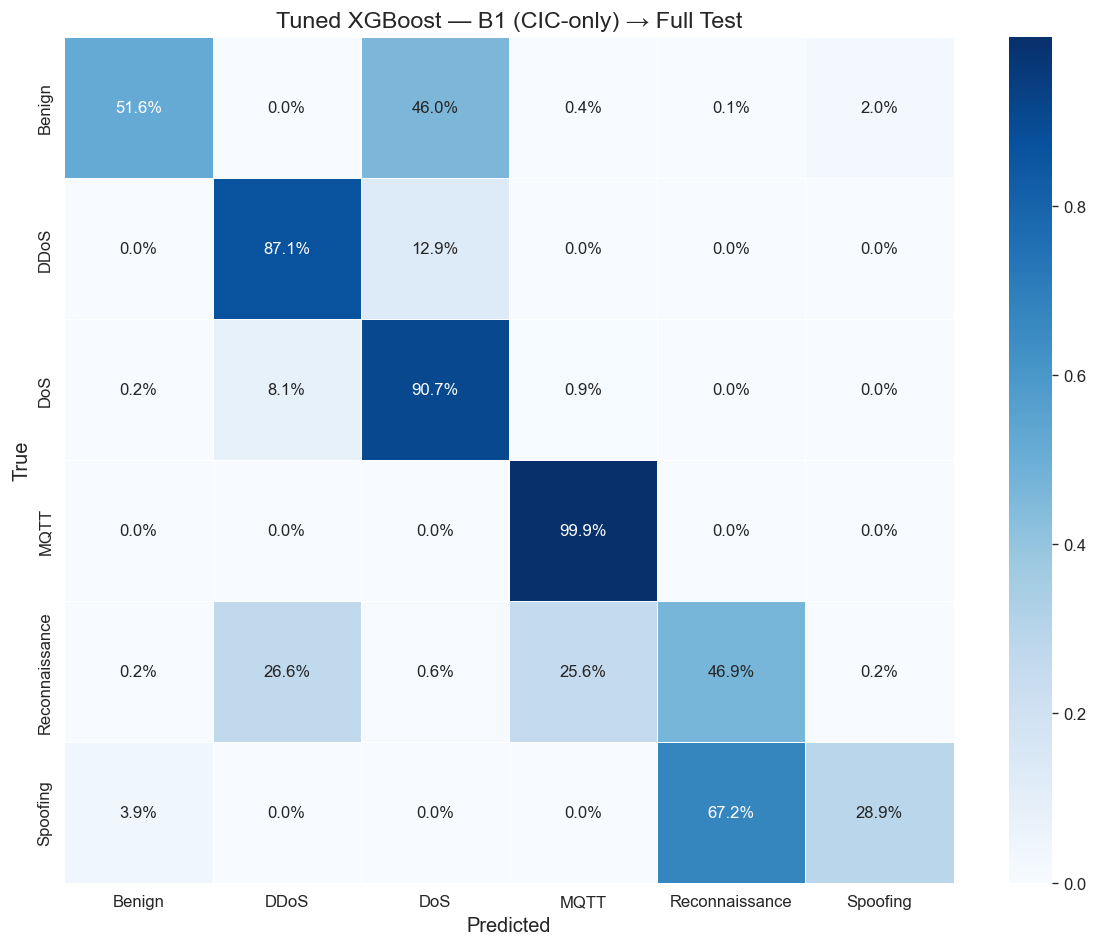

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_xgb_cm_b2_full.png


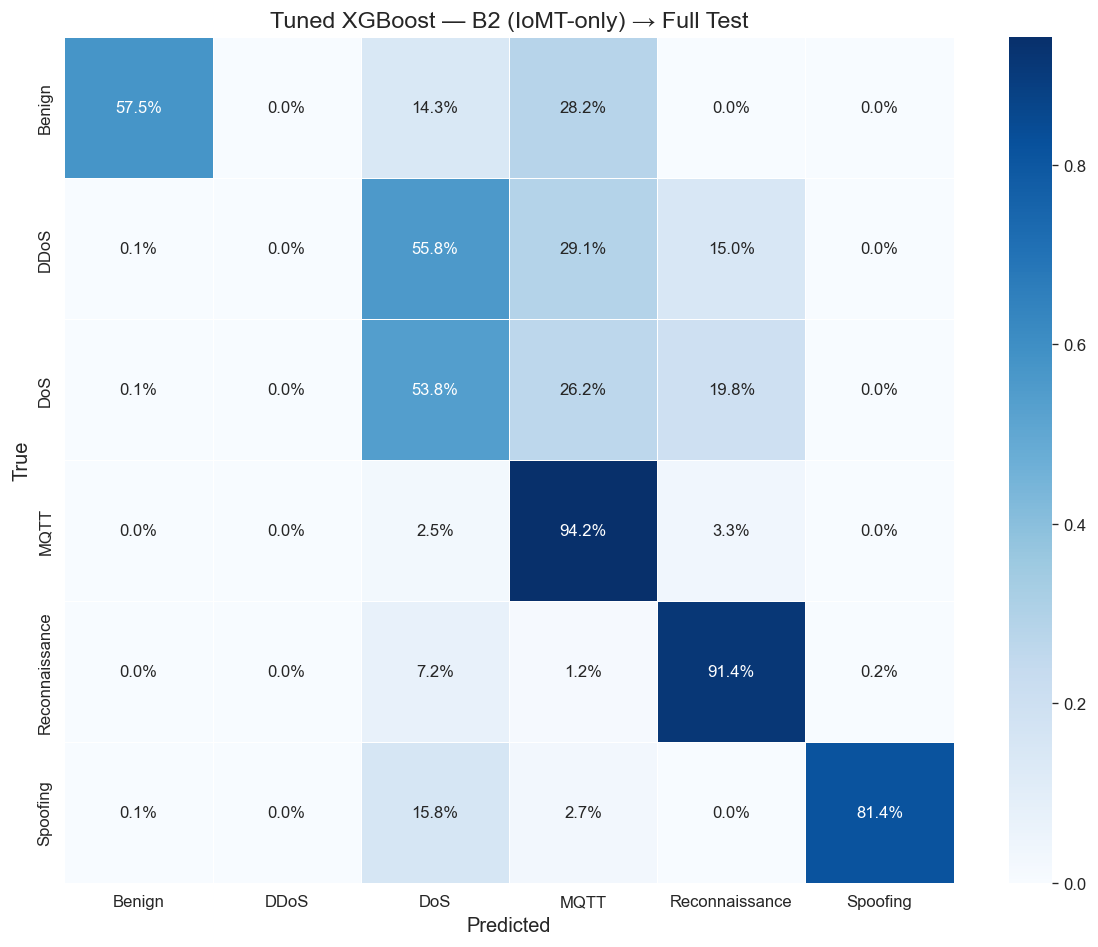

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_xgb_cm_u_full.png


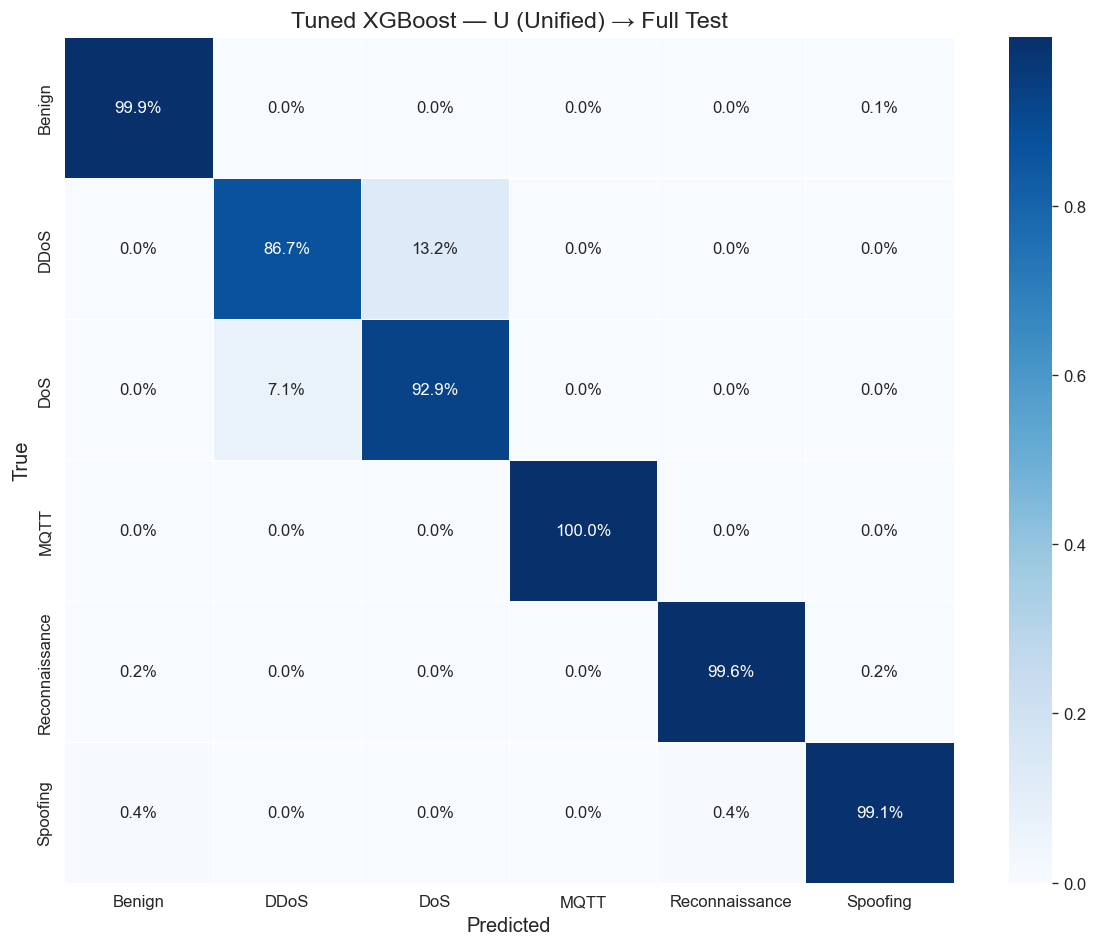

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_xgb_cm_b1_xd_iomt.png


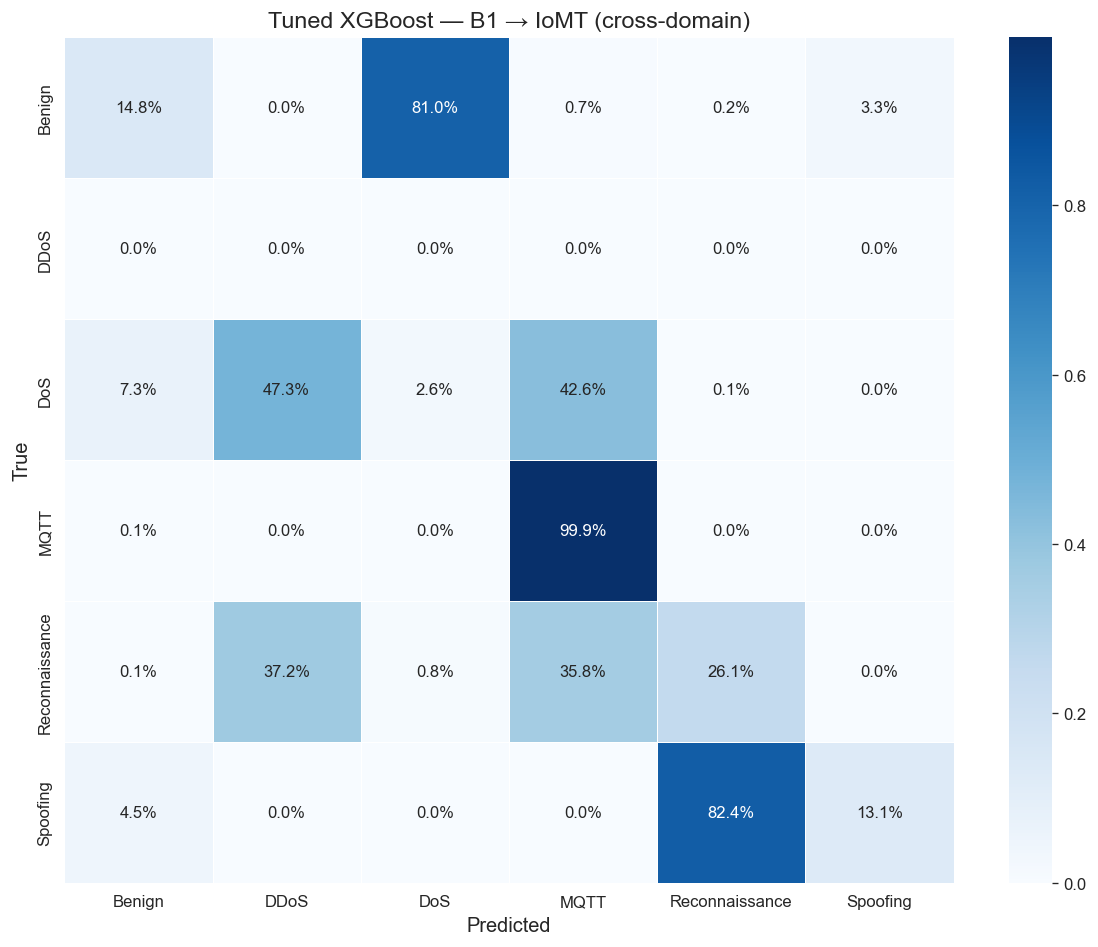

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_xgb_cm_b2_xd_cic.png


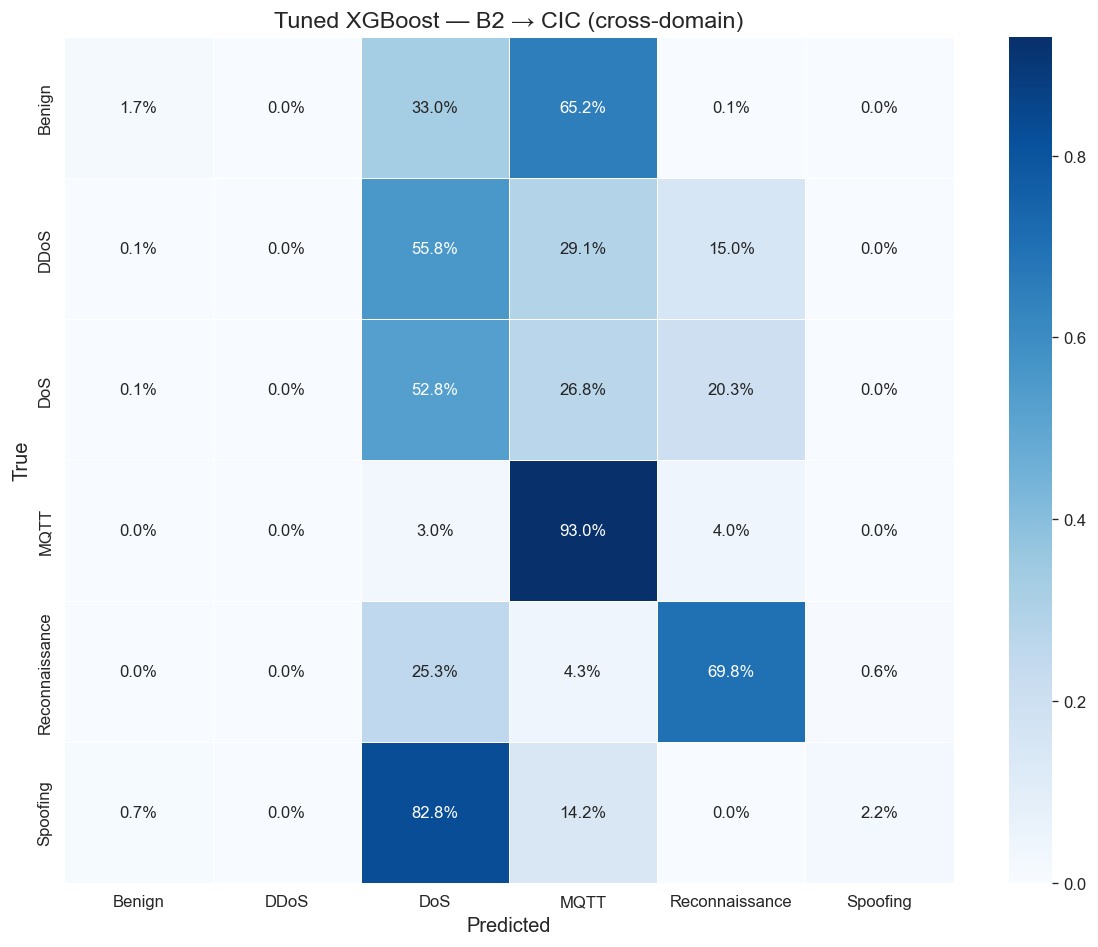

In [14]:
# --- Confusion Matrices (Tuned models, full test set) ---
for regime_key in ("B1", "B2", "U"):
    res_key = f"Tuned-{regime_key}"
    cm = tuned_xd_results[res_key]["full"]["cm"]
    fig = plot_confusion_matrix(
        cm, GLOBAL_CLASSES,
        title=f"Tuned XGBoost — {regime_key} ({REGIME_LABEL[regime_key]}) → Full Test",
        save_path=str(FIGURES_DIR / f"ch5_xgb_cm_{regime_key.lower()}_full.png"),
    )
    plt.show()
    plt.close(fig)

# Cross-domain confusion matrices
xd_pairs = [("B1", "IoMT-TrafficData", "IoMT"),
            ("B2", "CICIoMT2024", "CIC")]
for regime_key, other_src, tag in xd_pairs:
    res_key = f"Tuned-{regime_key}"
    if other_src in tuned_xd_results[res_key]:
        cm = tuned_xd_results[res_key][other_src]["cm"]
        fig = plot_confusion_matrix(
            cm, GLOBAL_CLASSES,
            title=f"Tuned XGBoost — {regime_key} → {tag} (cross-domain)",
            save_path=str(FIGURES_DIR / f"ch5_xgb_cm_{regime_key.lower()}_xd_{tag.lower()}.png"),
        )
        plt.show()
        plt.close(fig)

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_xgb_feature_importance_unified.png


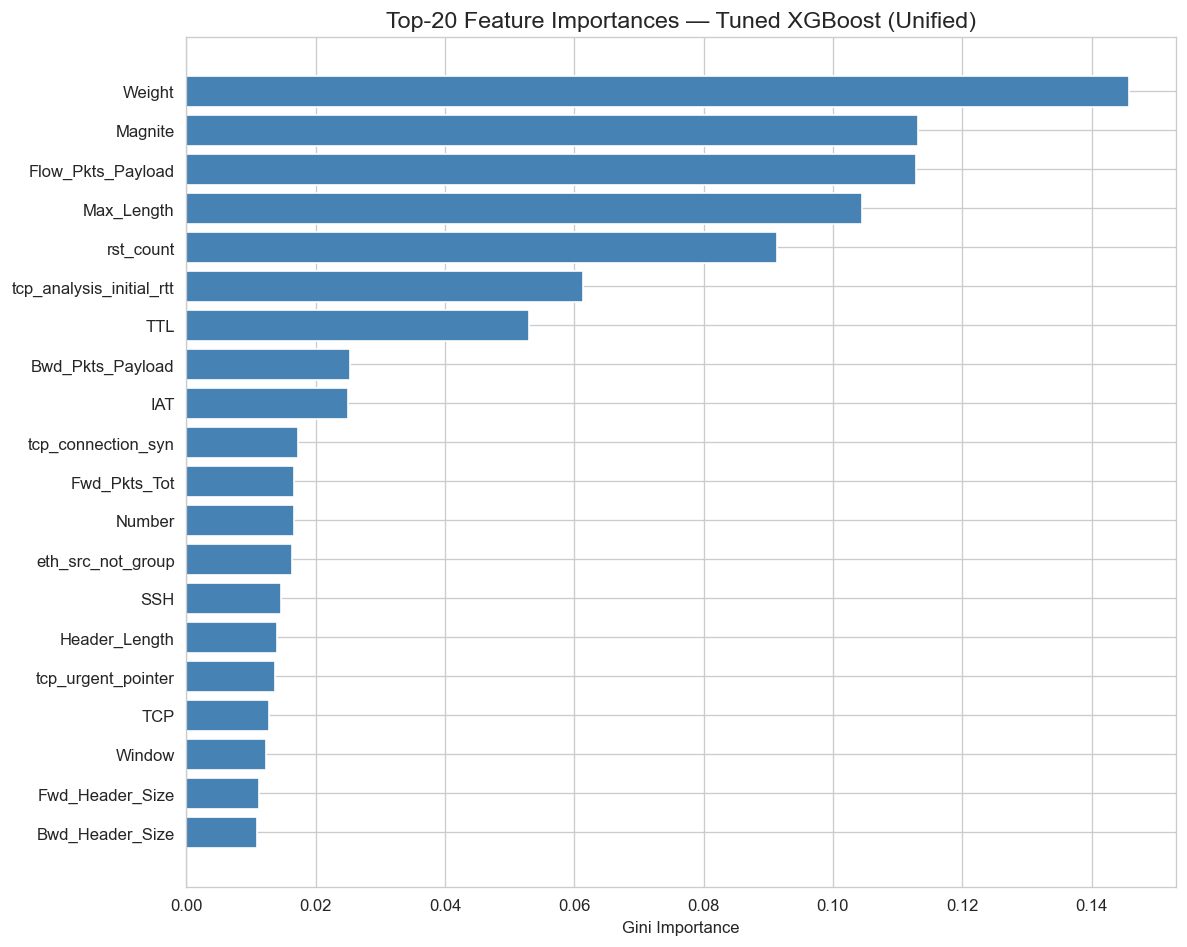

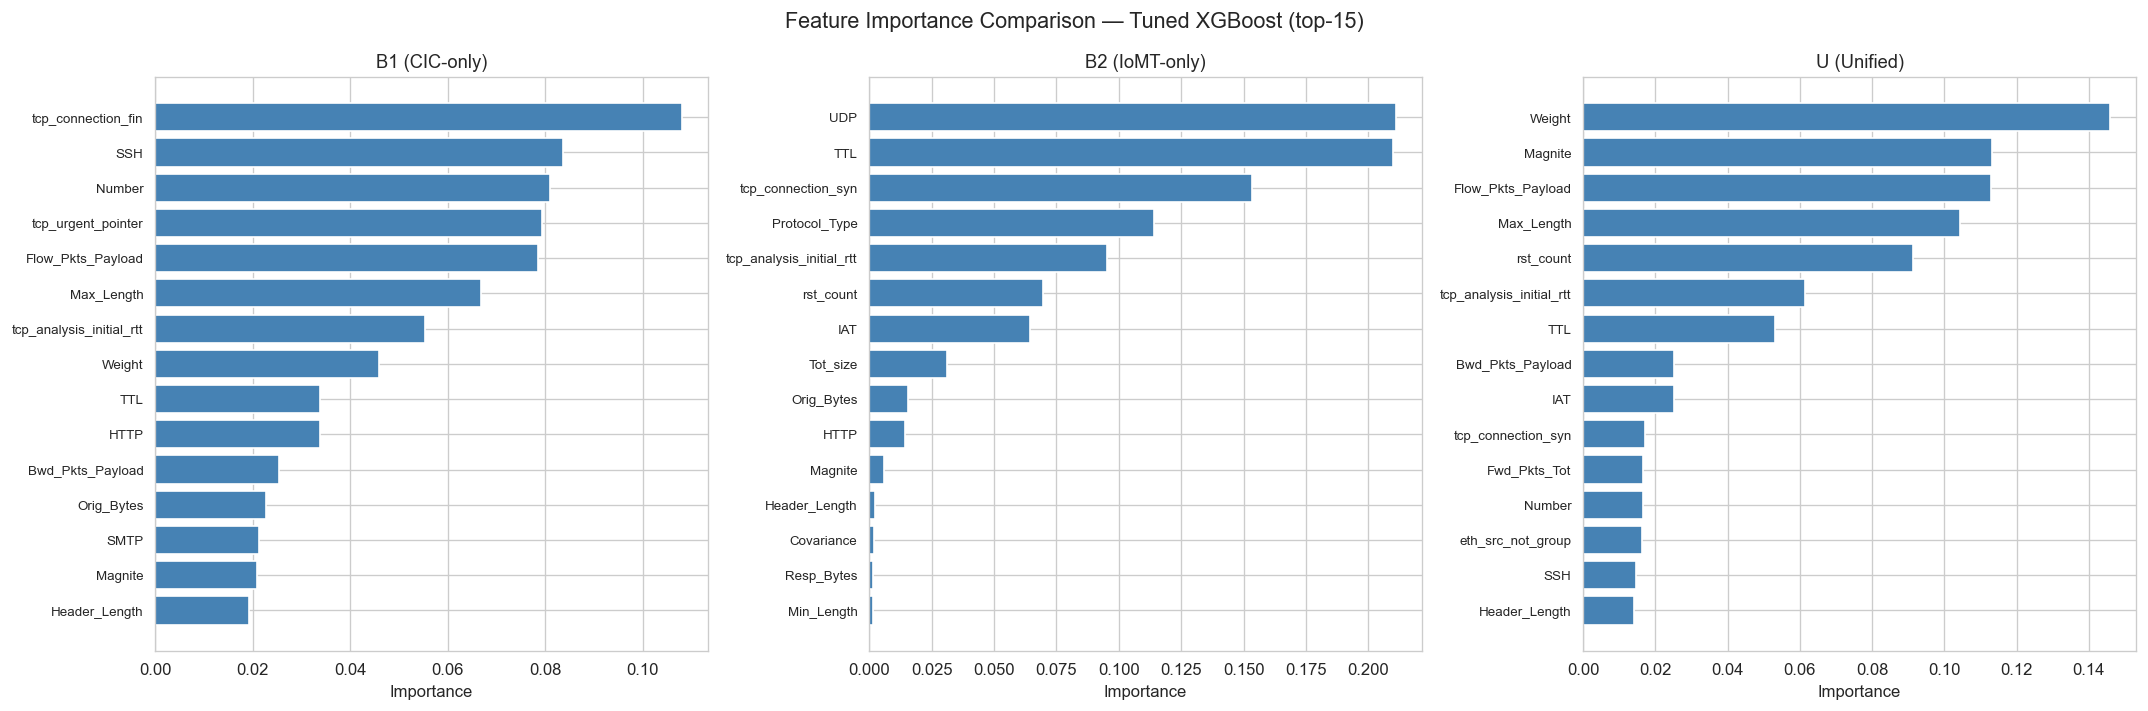

In [15]:
# --- Feature importance (Unified tuned XGBoost) ---
fig = plot_feature_importance(
    tuned_models["U"], feature_cols, top_n=20,
    title="Top-20 Feature Importances — Tuned XGBoost (Unified)",
    save_path=str(FIGURES_DIR / "ch5_xgb_feature_importance_unified.png"),
)
plt.show()
plt.close(fig)

# --- Feature importance comparison (3 regimes) ---
top_n = 15
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=False)
for ax, regime_key in zip(axes, ("B1", "B2", "U")):
    imp = tuned_models[regime_key].feature_importances_
    idx = np.argsort(imp)[::-1][:top_n]
    y_pos = np.arange(top_n)
    ax.barh(y_pos, imp[idx[::-1]], color="steelblue")
    ax.set_yticks(y_pos)
    ax.set_yticklabels([feature_cols[i] for i in idx[::-1]], fontsize=8)
    ax.set_title(f"{regime_key} ({REGIME_LABEL[regime_key]})", fontsize=11)
    ax.set_xlabel("Importance")
fig.suptitle("Feature Importance Comparison — Tuned XGBoost (top-15)", fontsize=13)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "ch5_xgb_feature_importance_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_xgb_regime_comparison.png


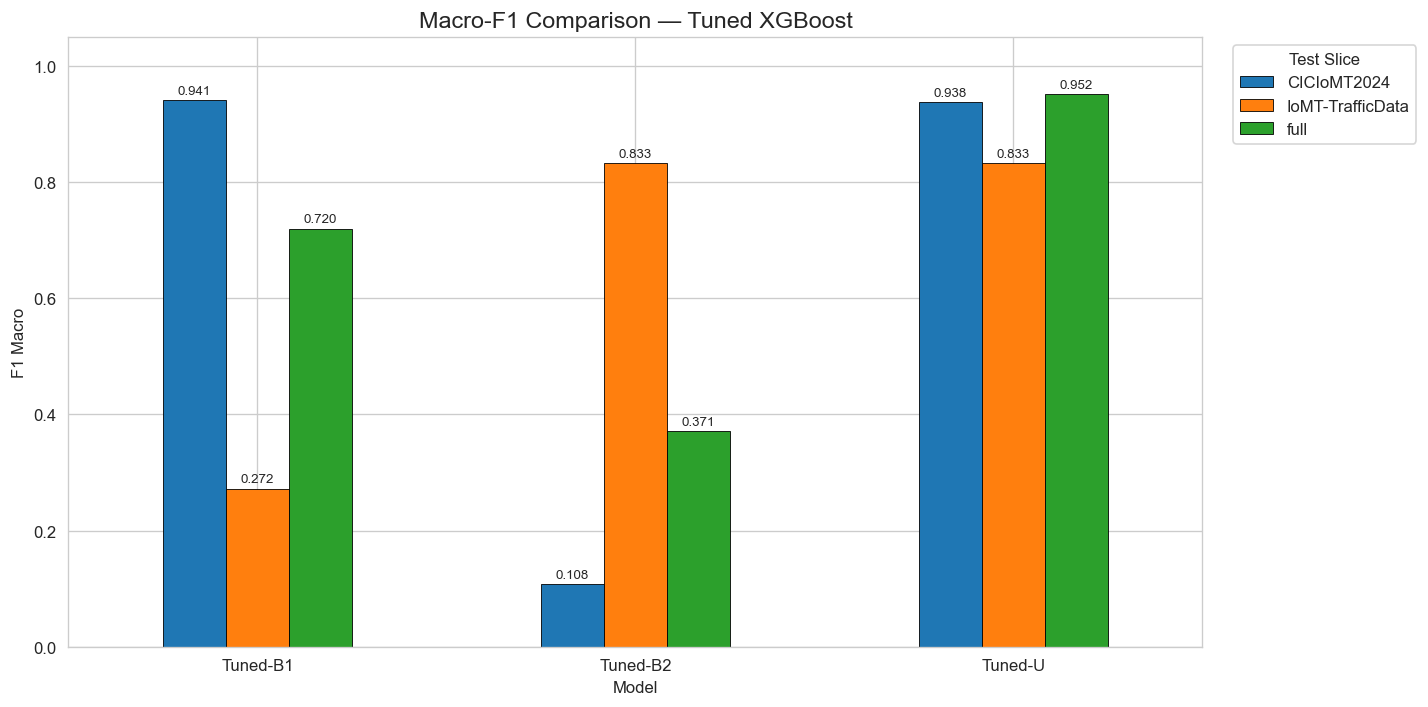

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_xgb_per_class_f1.png


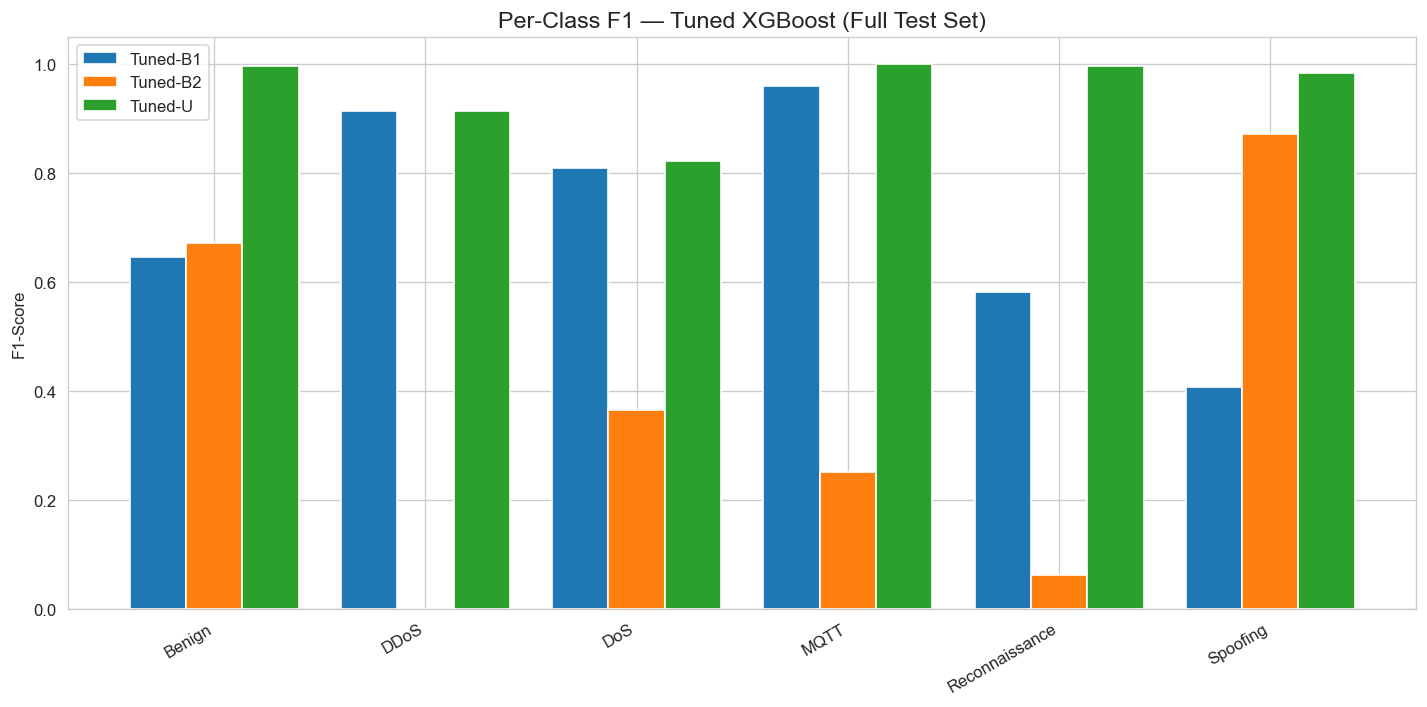

In [16]:
# --- Regime comparison (macro-F1) ---
fig = plot_regime_comparison(
    tuned_eval_df, metric="f1_macro",
    title="Macro-F1 Comparison — Tuned XGBoost",
    save_path=str(FIGURES_DIR / "ch5_xgb_regime_comparison.png"),
)
plt.show()
plt.close(fig)

# --- Per-class F1 ---
fig = plot_per_class_f1(
    tuned_xd_results, le, test_slice="full",
    title="Per-Class F1 — Tuned XGBoost (Full Test Set)",
    save_path=str(FIGURES_DIR / "ch5_xgb_per_class_f1.png"),
)
plt.show()
plt.close(fig)

## 9. Per-Class Analysis

In [17]:
from sklearn.metrics import classification_report as cr_text

for regime_key in ("B1", "B2", "U"):
    res_key = f"Tuned-{regime_key}"
    y_true = le.transform(splits["test"]["label_category"])
    y_pred = tuned_xd_results[res_key]["full"]["y_pred"]
    print("=" * 60)
    print(f"Classification Report — Tuned XGBoost {regime_key} ({REGIME_LABEL[regime_key]}) → Full Test")
    print("=" * 60)
    print(cr_text(y_true, y_pred, target_names=GLOBAL_CLASSES, zero_division=0, digits=2))
    print()

Classification Report — Tuned XGBoost B1 (CIC-only) → Full Test
                precision    recall  f1-score   support

        Benign       0.87      0.52      0.65      8018
          DDoS       0.96      0.87      0.91    805244
           DoS       0.73      0.91      0.81    322273
          MQTT       0.92      1.00      0.96     57891
Reconnaissance       0.77      0.47      0.58      6904
      Spoofing       0.69      0.29      0.41      1401

      accuracy                           0.88   1201731
     macro avg       0.82      0.68      0.72   1201731
  weighted avg       0.90      0.88      0.88   1201731




Classification Report — Tuned XGBoost B2 (IoMT-only) → Full Test
                precision    recall  f1-score   support

        Benign       0.81      0.57      0.67      8018
          DDoS       0.00      0.00      0.00    805244
           DoS       0.28      0.54      0.37    322273
          MQTT       0.15      0.94      0.25     57891
Reconnaissance       0.03      0.91      0.06      6904
      Spoofing       0.94      0.81      0.87      1401

      accuracy                           0.20   1201731
     macro avg       0.37      0.63      0.37   1201731
  weighted avg       0.09      0.20      0.12   1201731




Classification Report — Tuned XGBoost U (Unified) → Full Test
                precision    recall  f1-score   support

        Benign       0.99      1.00      1.00      8018
          DDoS       0.97      0.87      0.92    805244
           DoS       0.74      0.93      0.82    322273
          MQTT       1.00      1.00      1.00     57891
Reconnaissance       1.00      1.00      1.00      6904
      Spoofing       0.98      0.99      0.98      1401

      accuracy                           0.89   1201731
     macro avg       0.95      0.96      0.95   1201731
  weighted avg       0.91      0.89      0.90   1201731




In [18]:
from IPython.display import display, Markdown

b1_full = tuned_xd_results["Tuned-B1"]["full"]["metrics"]["f1_macro"]
b2_full = tuned_xd_results["Tuned-B2"]["full"]["metrics"]["f1_macro"]
u_full  = tuned_xd_results["Tuned-U"]["full"]["metrics"]["f1_macro"]
b1_xd   = tuned_xd_results["Tuned-B1"].get("IoMT-TrafficData", {}).get("metrics", {}).get("f1_macro", 0)
b2_xd   = tuned_xd_results["Tuned-B2"].get("CICIoMT2024", {}).get("metrics", {}).get("f1_macro", 0)
u_cic   = tuned_xd_results["Tuned-U"].get("CICIoMT2024", {}).get("metrics", {}).get("f1_macro", 0)
u_iomt  = tuned_xd_results["Tuned-U"].get("IoMT-TrafficData", {}).get("metrics", {}).get("f1_macro", 0)

summary_md = f"""## 10. Summary — XGBoost

| Metric | B1 (CIC-only) | B2 (IoMT-only) | U (Unified) |
|--------|--------------|----------------|-------------|
| **Full test macro-F1** | {b1_full:.4f} | {b2_full:.4f} | **{u_full:.4f}** |
| Cross-domain macro-F1 | {b1_xd:.4f} (→IoMT) | {b2_xd:.4f} (→CIC) | CIC={u_cic:.4f} / IoMT={u_iomt:.4f} |

**Key findings:**
- Unified XGBoost achieves macro-F1 = {u_full:.4f} on the full test set.
- Absolute improvement over best single-source: +{(u_full - max(b1_full, b2_full))*100:.1f} pp.
- Single-source models still fail cross-domain (B1→IoMT: {b1_xd:.4f}, B2→CIC: {b2_xd:.4f}).

Next: Model Comparison across DT, RF, XGBoost.
"""
display(Markdown(summary_md))

## 10. Summary — XGBoost

| Metric | B1 (CIC-only) | B2 (IoMT-only) | U (Unified) |
|--------|--------------|----------------|-------------|
| **Full test macro-F1** | 0.7199 | 0.3708 | **0.9522** |
| Cross-domain macro-F1 | 0.2724 (→IoMT) | 0.1079 (→CIC) | CIC=0.9382 / IoMT=0.8333 |

**Key findings:**
- Unified XGBoost achieves macro-F1 = 0.9522 on the full test set.
- Absolute improvement over best single-source: +23.2 pp.
- Single-source models still fail cross-domain (B1→IoMT: 0.2724, B2→CIC: 0.1079).

Next: Model Comparison across DT, RF, XGBoost.
